# Wildlife AI — ResNet50 Training (Snapshot Serengeti S3)
**Tasks**: Species classification + Day/Night + Empty frame detection
**Architecture**: ResNet50 with transfer learning
**Dataset**: Snapshot Serengeti Season 3

## 1. Imports

In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from collections import Counter
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image

# GPU check
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


Device: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
VRAM: 8.6 GB


## 2. Configuration — Update paths here

In [2]:
# ============================================================
# UPDATE THESE PATHS
# ============================================================
IMAGES_DIR   = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\PROJECT\data'
JSON_PATH = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\Datset\Serenegetijson\SnapshotSerengetiS03.json'
OUTPUT_DIR   = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\Wildlife-AI-Monitoring-System-using-Camera-trap-images\models\trained_models'
DATA_DIR     = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\Wildlife-AI-Monitoring-System-using-Camera-trap-images\data'
# ============================================================

# Species to include — category_ids from JSON
# 0=empty, 5=zebra, 8=hyenaspotted, 10=impala, 13=giraffe,
# 18=wildebeest, 19=leopard, 21=lionfemale, 24=cheetah, 39=lionmale
TARGET_SPECIES = {
    0:  'empty',
    5:  'zebra',
    8:  'hyenaspotted',
    10: 'impala',
    13: 'giraffe',
    18: 'wildebeest',
    19: 'leopard',
    21: 'lion',   # lionfemale -> lion
    24: 'cheetah',
    39: 'lion',   # lionmale -> lion (combined)
}

# Max images per class (to balance dataset)
MAX_PER_CLASS = {
    'empty':        3000,
    'zebra':        3000,
    'wildebeest':   3000,
    'giraffe':      3000,
    'impala':       2000,
    'lion':         1500,
    'hyenaspotted': 1000,
    'cheetah':       245,
    'leopard':        29,
}

# Training config
IMG_SIZE      = 224
BATCH_SIZE    = 32
NUM_EPOCHS    = 25
LEARNING_RATE = 1e-4
VAL_SPLIT     = 0.2
WARMUP_EPOCHS = 3
DAY_START     = 6
DAY_END       = 18

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
print('Config ready.')
print(f'Target species: {list(set(TARGET_SPECIES.values()))}')
print('again11')


Config ready.
Target species: ['cheetah', 'empty', 'wildebeest', 'lion', 'leopard', 'impala', 'zebra', 'hyenaspotted', 'giraffe']
again11


## 3. Load JSON & Build Image-Label Mapping

In [3]:
print('Loading JSON......')
with open(JSON_PATH, 'r') as f:
    data = json.load(f)

print(f'Total images in JSON:      {len(data["images"])}')
print(f'Total annotations in JSON: {len(data["annotations"])}')
print(f'Total categories:          {len(data["categories"])}')


Loading JSON......
Total images in JSON:      392507
Total annotations in JSON: 398689
Total categories:          61


In [4]:
def get_time_of_day(datetime_str):
    try:
        dt = datetime.strptime(str(datetime_str), '%Y-%m-%d %H:%M:%S')
        return 'day' if DAY_START <= dt.hour < DAY_END else 'night'
    except:
        return 'unknown'

# Build image_id -> file path lookup
# image_id: 'S3/B04/B04_R11/S3_B04_R11_IMAG0004'
# filename:  'S3_B04_R11_IMAG0004.JPG'
print('Building image lookup...')
image_lookup = {}
for img in tqdm(data['images']):
    img_id   = img['id']                        # e.g. S3/B04/B04_R11/S3_B04_R11_IMAG0004
    filename = img_id.split('/')[-1] + '.JPG'   # e.g. S3_B04_R11_IMAG0004.JPG
    full_path = os.path.join(IMAGES_DIR, filename)
    image_lookup[img_id] = {
        'path':        full_path,
        'exists':      os.path.exists(full_path),
        'datetime':    img.get('datetime', ''),
        'time_of_day': get_time_of_day(img.get('datetime', '')),
    }

existing = sum(1 for v in image_lookup.values() if v['exists'])
print(f'Images found on disk: {existing} / {len(image_lookup)}')


Building image lookup...


100%|████████████████████████████████████████████████████████████████████████| 392507/392507 [00:40<00:00, 9615.64it/s]

Images found on disk: 81860 / 392507


In [5]:
print('Building annotation records...')
records = []
skipped = 0

for ann in tqdm(data['annotations']):
    cat_id  = ann['category_id']
    img_id  = ann['image_id']

    # Only include target species
    if cat_id not in TARGET_SPECIES:
        skipped += 1
        continue

    species = TARGET_SPECIES[cat_id]

    # Check image exists on disk
    img_info = image_lookup.get(img_id)
    if img_info is None or not img_info['exists']:
        skipped += 1
        continue

    records.append({
        'image_path': img_info['path'],
        'species':    species,
        'time_of_day': img_info['time_of_day'],
        'is_empty':   1 if species == 'empty' else 0,
        'image_id':   img_id,
    })

full_df = pd.DataFrame(records)
print(f'Total records: {len(full_df)} | Skipped: {skipped}')
print('\nRaw species counts:')
print(full_df['species'].value_counts())


Building annotation records...


100%|██████████████████████████████████████████████████████████████████████| 398689/398689 [00:00<00:00, 702644.76it/s]


Total records: 86618 | Skipped: 312071

Raw species counts:
species
wildebeest      46896
zebra           28510
giraffe          3166
empty            3000
impala           2019
lion             1615
hyenaspotted     1138
cheetah           245
leopard            29
Name: count, dtype: int64


## 4. Balance Dataset — Cap Per Class

Balancing dataset...
  empty: 3000 available -> using 3000
  zebra: 28510 available -> using 3000
  wildebeest: 46896 available -> using 3000
  giraffe: 3166 available -> using 3000
  impala: 2019 available -> using 2000
  lion: 1615 available -> using 1500
  hyenaspotted: 1138 available -> using 1000
  cheetah: 245 available -> using 245
  leopard: 29 available -> using 29

Total balanced dataset: 16774 images


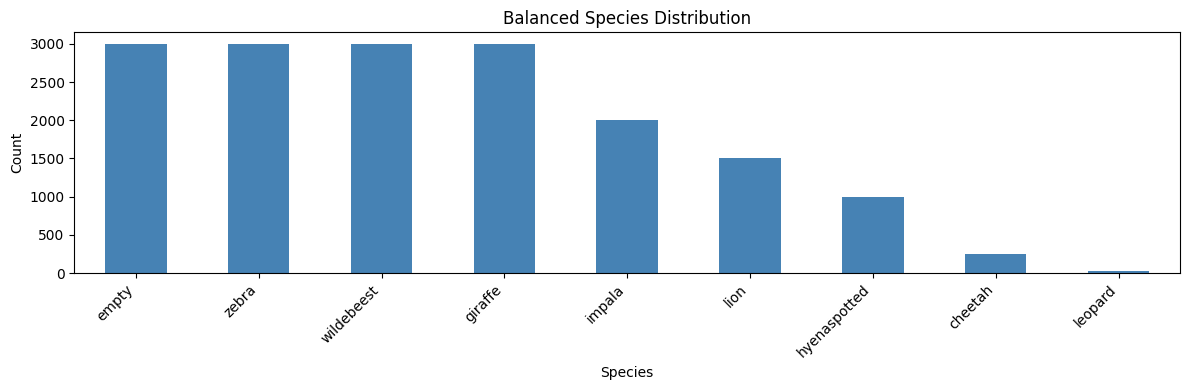

In [6]:
print('Balancing dataset...')
balanced_dfs = []

for species, max_count in MAX_PER_CLASS.items():
    subset = full_df[full_df['species'] == species]
    if len(subset) == 0:
        print(f'  WARNING: No images found for {species}')
        continue
    # Sample up to max_count, use all if fewer available
    n = min(len(subset), max_count)
    sampled = subset.sample(n=n, random_state=42)
    balanced_dfs.append(sampled)
    print(f'  {species}: {len(subset)} available -> using {n}')

balanced_df = pd.concat(balanced_dfs).reset_index(drop=True)
print(f'\nTotal balanced dataset: {len(balanced_df)} images')

# Plot distribution
plt.figure(figsize=(12, 4))
balanced_df['species'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Balanced Species Distribution')
plt.xlabel('Species')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'species_distribution.png'), dpi=150)
plt.show()


In [7]:
import os
save_dir = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\data\serengeti'
os.makedirs(save_dir, exist_ok=True)
balanced_df.to_csv(os.path.join(save_dir, 'image_label_mapping.csv'), index=False)
print('Serengeti mapping saved!')
print(balanced_df['species'].value_counts())

Serengeti mapping saved!
species
empty           3000
zebra           3000
wildebeest      3000
giraffe         3000
impala          2000
lion            1500
hyenaspotted    1000
cheetah          245
leopard           29
Name: count, dtype: int64


## 5. Label Encoding

In [34]:
species_classes = sorted(balanced_df['species'].unique().tolist())
species2idx     = {s: i for i, s in enumerate(species_classes)}
idx2species     = {i: s for s, i in species2idx.items()}

tod_classes = ['day', 'night', 'unknown']
tod2idx     = {t: i for i, t in enumerate(tod_classes)}

balanced_df['species_label'] = balanced_df['species'].map(species2idx)
balanced_df['tod_label']     = balanced_df['time_of_day'].map(tod2idx).fillna(2).astype(int)

print(f'Species classes ({len(species_classes)}): {species_classes}')

# Save label map
label_map = {
    'species_classes': species_classes,
    'species2idx':     species2idx,
    'idx2species':     idx2species,
    'tod_classes':     tod_classes,
    'tod2idx':         tod2idx,
}
with open(os.path.join(OUTPUT_DIR, 'label_map.json'), 'w') as f:
    json.dump(label_map, f, indent=2)
print('Label map saved.')


Species classes (9): ['cheetah', 'empty', 'giraffe', 'hyenaspotted', 'impala', 'leopard', 'lion', 'wildebeest', 'zebra']
Label map saved.


## 6. Train/Val Split

In [35]:
train_df, val_df = train_test_split(
    balanced_df,
    test_size=VAL_SPLIT,
    stratify=balanced_df['species_label'],
    random_state=42
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
print(f'Train: {len(train_df)} | Val: {len(val_df)}')
print('Train distribution:')
print(train_df['species'].value_counts())


Train: 13419 | Val: 3355
Train distribution:
species
zebra           2400
giraffe         2400
wildebeest      2400
empty           2400
impala          1600
lion            1200
hyenaspotted     800
cheetah          196
leopard           23
Name: count, dtype: int64


## 7. Dataset & DataLoaders

In [36]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),   # helps with night images
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class WildlifeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row['image_path']).convert('RGB')
        except Exception:
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (0, 0, 0))
        if self.transform:
            image = self.transform(image)
        return {
            'image':         image,
            'species_label': torch.tensor(int(row['species_label']), dtype=torch.long),
            'tod_label':     torch.tensor(int(row['tod_label']),     dtype=torch.long),
            'is_empty':      torch.tensor(float(row['is_empty']),    dtype=torch.float),
        }

train_dataset = WildlifeDataset(train_df, transform=train_transforms)
val_dataset   = WildlifeDataset(val_df,   transform=val_transforms)

# Weighted sampler for class imbalance
class_counts   = train_df['species_label'].value_counts().sort_index().values
class_weights  = 1.0 / class_counts
sample_weights = class_weights[train_df['species_label'].values]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,    num_workers=0, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')


Train batches: 420 | Val batches: 105


## 8. Model — Multi-task ResNet50

In [37]:
class WildlifeResNet(nn.Module):
    def __init__(self, num_species):
        super().__init__()
        backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone

        self.species_head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_species),
        )
        self.tod_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 3),
        )
        self.empty_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        features = self.backbone(x)
        return {
            'species': self.species_head(features),
            'tod':     self.tod_head(features),
            'empty':   self.empty_head(features).squeeze(1),
        }

num_species = len(species_classes)
model = WildlifeResNet(num_species=num_species).to(device)
print(f'Model ready — {num_species} species classes')

# Freeze backbone for warmup
for param in model.backbone.parameters():
    param.requires_grad = False
print(f'Backbone frozen for {WARMUP_EPOCHS} warmup epochs.')


Model ready — 9 species classes
Backbone frozen for 3 warmup epochs.


## 9. Loss Functions & Optimizer

In [38]:
# Focal loss for species — handles class imbalance better than CrossEntropy
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, reduction='mean'):
        super().__init__()
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        focal   = ((1 - pt) ** self.gamma) * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()

species_loss_fn = FocalLoss(gamma=2.0)       # focal loss for imbalanced species
tod_loss_fn     = nn.CrossEntropyLoss()       # standard for day/night
empty_loss_fn   = nn.BCEWithLogitsLoss()      # binary for empty detection

# Loss weights
W_SPECIES = 1.0
W_TOD     = 0.3
W_EMPTY   = 0.5

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
print('Loss functions and optimizer ready.')
print('Using Focal Loss for species classification (gamma=2.0)')


Loss functions and optimizer ready.
Using Focal Loss for species classification (gamma=2.0)


## 10. Training Loop

In [39]:
def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss      = 0
    species_correct = 0
    tod_correct     = 0
    empty_correct   = 0
    total           = 0

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in tqdm(loader, leave=False):
            images       = batch['image'].to(device)
            sp_labels    = batch['species_label'].to(device)
            tod_labels   = batch['tod_label'].to(device)
            empty_labels = batch['is_empty'].to(device)

            outputs = model(images)

            loss_sp  = species_loss_fn(outputs['species'], sp_labels)
            loss_tod = tod_loss_fn(outputs['tod'], tod_labels)
            loss_emp = empty_loss_fn(outputs['empty'], empty_labels)
            loss     = W_SPECIES * loss_sp + W_TOD * loss_tod + W_EMPTY * loss_emp

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss      += loss.item() * len(images)
            total           += len(images)
            species_correct += (outputs['species'].argmax(1) == sp_labels).sum().item()
            tod_correct     += (outputs['tod'].argmax(1) == tod_labels).sum().item()
            empty_pred       = (torch.sigmoid(outputs['empty']) > 0.5).float()
            empty_correct   += (empty_pred == empty_labels).sum().item()

    return {
        'loss':        total_loss / total,
        'species_acc': species_correct / total,
        'tod_acc':     tod_correct / total,
        'empty_acc':   empty_correct / total,
    }

# Load checkpoint to resume
checkpoint = torch.load(
    os.path.join(OUTPUT_DIR, 'resnet50_serengeti_best.pth'),
    map_location=device, weights_only=False
)
model.load_state_dict(checkpoint['model_state_dict'])
best_val_acc = checkpoint['val_species_acc']

# Unfreeze backbone — we're past warmup
for param in model.backbone.parameters():
    param.requires_grad = True
optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=4)

history = {'train': [], 'val': []}
RESUME_FROM = 21

print(f'Resuming from epoch 21, best acc so far: {best_val_acc:.3f}')
print('-' * 70)
for epoch in range(RESUME_FROM + 1, NUM_EPOCHS + 1):

    # Unfreeze backbone after warmup
    if epoch == WARMUP_EPOCHS + 1:
        print('Unfreezing backbone — starting full fine-tuning...')
        for param in model.backbone.parameters():
            param.requires_grad = True
        optimizer = optim.AdamW(
            model.parameters(),
            lr=LEARNING_RATE * 0.1,
            weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS
        )

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics   = run_epoch(val_loader,   training=False)
    scheduler.step()

    history['train'].append(train_metrics)
    history['val'].append(val_metrics)
    # Save history to disk
    with open(os.path.join(OUTPUT_DIR, 'training_history.json'), 'w') as f:
        json.dump(history, f)
    
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Species: {val_metrics['species_acc']:.3f} | "
        f"Val Empty: {val_metrics['empty_acc']:.3f} | "
        f"Val ToD: {val_metrics['tod_acc']:.3f}"
    )

    if val_metrics['species_acc'] > best_val_acc:
        best_val_acc = val_metrics['species_acc']
        torch.save({
            'epoch':              epoch,
            'model_state_dict':   model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_species_acc':    best_val_acc,
            'num_species':        num_species,
            'species_classes':    species_classes,
            'tod_classes':        tod_classes,
        }, os.path.join(OUTPUT_DIR, 'resnet50_serengeti_best.pth'))
        print(f'  -> Best model saved (val acc: {best_val_acc:.3f})')

print('Training complete!')
print(f'Best validation species accuracy: {best_val_acc:.3f}')


Resuming from epoch 21, best acc so far: 0.903
----------------------------------------------------------------------


Epoch 22/25 | Train Loss: 0.1867 | Val Loss: 0.2235 | Val Species: 0.904 | Val Empty: 0.964 | Val ToD: 0.962
  -> Best model saved (val acc: 0.904)


Epoch 23/25 | Train Loss: 0.1867 | Val Loss: 0.2158 | Val Species: 0.907 | Val Empty: 0.965 | Val ToD: 0.962
  -> Best model saved (val acc: 0.907)


Epoch 24/25 | Train Loss: 0.1760 | Val Loss: 0.2169 | Val Species: 0.906 | Val Empty: 0.966 | Val ToD: 0.963


Epoch 25/25 | Train Loss: 0.1712 | Val Loss: 0.2156 | Val Species: 0.907 | Val Empty: 0.966 | Val ToD: 0.964
  -> Best model saved (val acc: 0.907)
Training complete!
Best validation species accuracy: 0.907


## 11. Training Curves

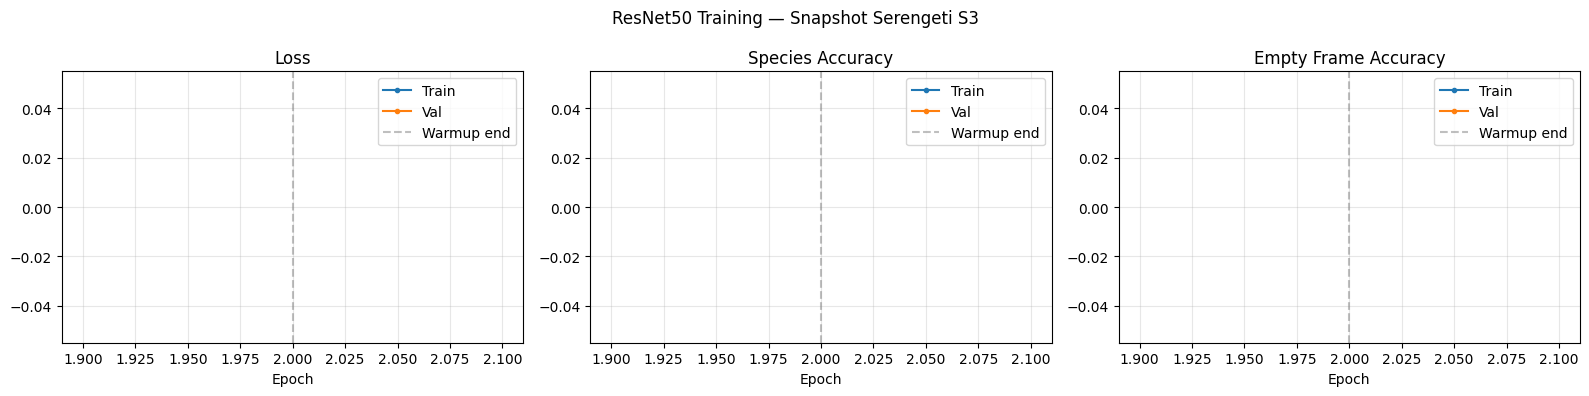

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ['loss', 'species_acc', 'empty_acc']
titles  = ['Loss', 'Species Accuracy', 'Empty Frame Accuracy']

for ax, metric, title in zip(axes, metrics, titles):
    ax.plot([m[metric] for m in history['train']], label='Train', marker='o', markersize=3)
    ax.plot([m[metric] for m in history['val']],   label='Val',   marker='o', markersize=3)
    ax.axvline(x=WARMUP_EPOCHS - 1, color='gray', linestyle='--', alpha=0.5, label='Warmup end')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('ResNet50 Training — Snapshot Serengeti S3', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves.png'), dpi=150)
plt.show()


In [41]:
import json, os, torch

OUTPUT_DIR = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\Wildlife-AI-Monitoring-System-using-Camera-trap-images\models\trained_models'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

with open(os.path.join(OUTPUT_DIR, 'label_map.json'), 'r') as f:
    label_map = json.load(f)

species_classes = label_map['species_classes']
tod_classes     = label_map['tod_classes']
num_species     = len(species_classes)
print(f'Species classes ({num_species}): {species_classes}')
print(f'Device: {device}')

Species classes (9): ['cheetah', 'empty', 'giraffe', 'hyenaspotted', 'impala', 'leopard', 'lion', 'wildebeest', 'zebra']
Device: cuda


In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGES_DIR = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\PROJECT\data'
DATA_DIR   = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\Wildlife-AI-Monitoring-System-using-Camera-trap-images\data'
IMG_SIZE   = 224
BATCH_SIZE = 32
VAL_SPLIT  = 0.2

# Load saved mapping
mapping_path = os.path.join(DATA_DIR, 'image_label_mapping.csv')
if os.path.exists(mapping_path):
    balanced_df = pd.read_csv(mapping_path)
    print(f'Loaded mapping: {len(balanced_df)} records')
    print(balanced_df['species'].value_counts())
else:
    print('ERROR: image_label_mapping.csv not found in DATA_DIR')

ERROR: image_label_mapping.csv not found in DATA_DIR


## 12. Evaluation

In [43]:
# Load best model
checkpoint = torch.load(
    os.path.join(OUTPUT_DIR, 'resnet50_serengeti_best.pth'),
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded best model from epoch {checkpoint["epoch"]}')

all_sp_preds, all_sp_labels = [], []

with torch.no_grad():
    for batch in tqdm(val_loader):
        images    = batch['image'].to(device)
        sp_labels = batch['species_label']
        outputs   = model(images)
        preds     = outputs['species'].argmax(1).cpu()
        all_sp_preds.extend(preds.numpy())
        all_sp_labels.extend(sp_labels.numpy())

print('\nClassification Report:')
print(classification_report(
    all_sp_labels, all_sp_preds,
    target_names=species_classes,
    zero_division=0
))


Loaded best model from epoch 25


100%|████████████████████████████████████████████████████████████████████████████████| 105/105 [05:59<00:00,  3.43s/it]


Classification Report:
              precision    recall  f1-score   support

     cheetah       0.88      0.94      0.91        49
       empty       0.89      0.93      0.91       600
     giraffe       0.96      0.94      0.95       600
hyenaspotted       0.91      0.94      0.92       200
      impala       0.97      0.97      0.97       400
     leopard       0.60      0.50      0.55         6
        lion       0.93      0.95      0.94       300
  wildebeest       0.84      0.89      0.86       600
       zebra       0.89      0.81      0.85       600

    accuracy                           0.91      3355
   macro avg       0.87      0.87      0.87      3355
weighted avg       0.91      0.91      0.91      3355



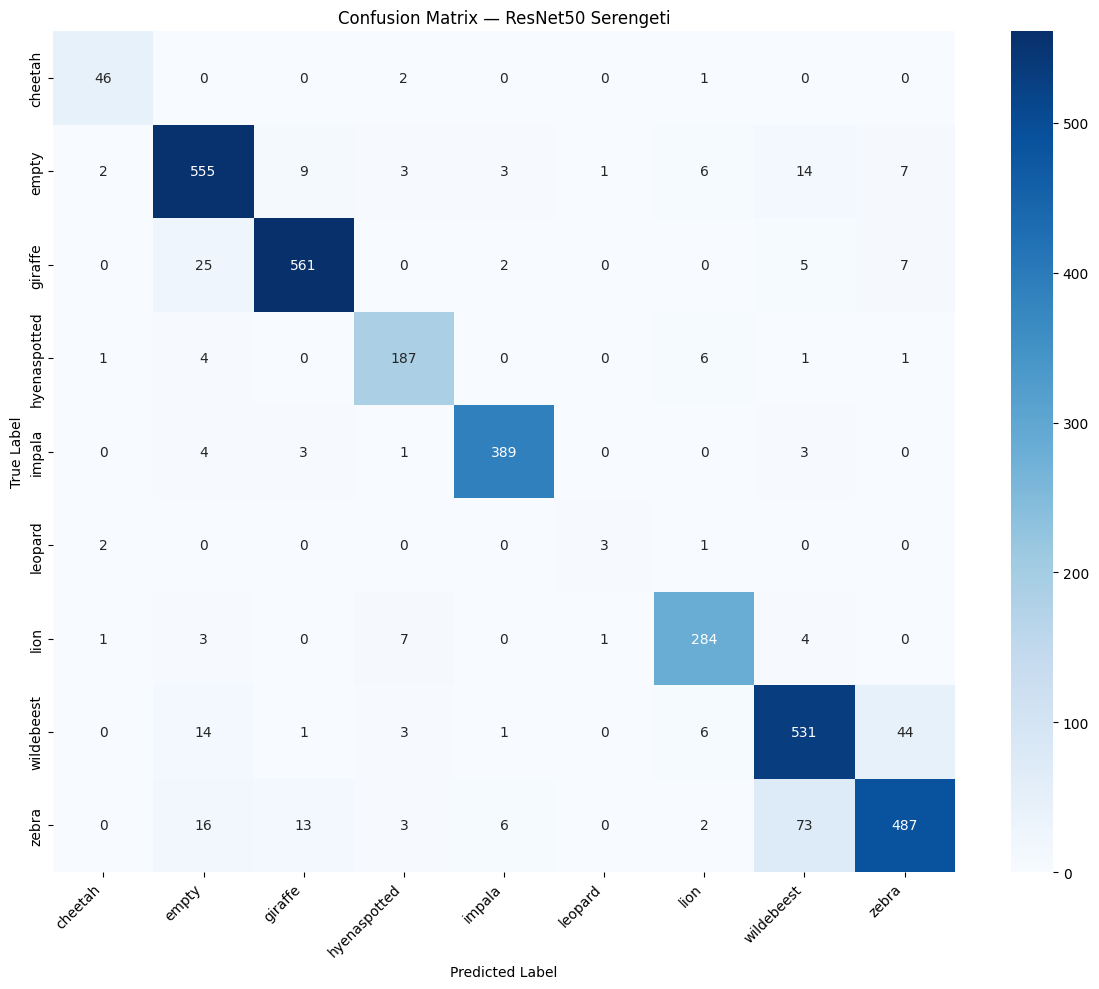

In [44]:
# Confusion matrix
cm = confusion_matrix(all_sp_labels, all_sp_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=species_classes,
    yticklabels=species_classes
)
plt.title('Confusion Matrix — ResNet50 Serengeti')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()


## 13. Single Image Inference Test

Image:      C:\Users\dippe\Desktop\University of Botswana\Semester 8\PROJECT\data\S3_M08_R12_IMAG0920.JPG
True:       lion
Predicted:  lion (98.02%)
Time:       day
Empty:      False
Top 3:      [{'species': 'lion', 'confidence': 98.02}, {'species': 'wildebeest', 'confidence': 0.78}, {'species': 'hyenaspotted', 'confidence': 0.76}]


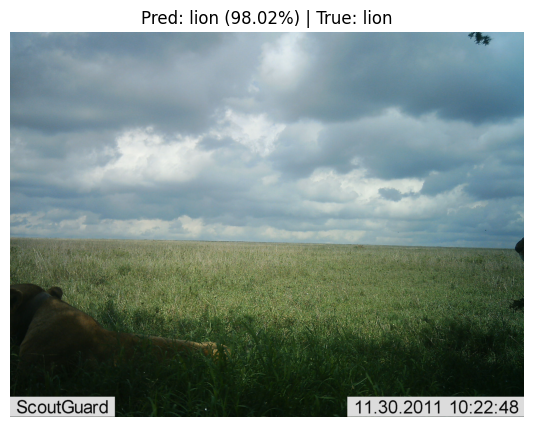

In [45]:
def predict_image(image_path, model, label_map, device):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    image  = Image.open(image_path).convert('RGB')
    tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(tensor)

    species_probs = torch.softmax(outputs['species'], dim=1)[0]
    species_idx   = species_probs.argmax().item()
    species_conf  = species_probs[species_idx].item()
    tod_idx       = outputs['tod'].argmax(1).item()
    is_empty      = torch.sigmoid(outputs['empty']).item() > 0.5

    return {
        'species':     label_map['species_classes'][species_idx],
        'confidence':  round(species_conf * 100, 2),
        'time_of_day': label_map['tod_classes'][tod_idx],
        'is_empty':    bool(is_empty),
        'top3': [
            {
                'species':    label_map['species_classes'][i],
                'confidence': round(species_probs[i].item() * 100, 2)
            }
            for i in species_probs.topk(3).indices.tolist()
        ]
    }

# Test on a random validation image
sample = val_df.sample(1).iloc[0]
result = predict_image(sample['image_path'], model, label_map, device)

print(f'Image:      {sample["image_path"]}')
print(f'True:       {sample["species"]}')
print(f'Predicted:  {result["species"]} ({result["confidence"]}%)')
print(f'Time:       {result["time_of_day"]}')
print(f'Empty:      {result["is_empty"]}')
print(f'Top 3:      {result["top3"]}')

img = Image.open(sample['image_path'])
plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.title(f'Pred: {result["species"]} ({result["confidence"]}%) | True: {sample["species"]}')
plt.axis('off')
plt.show()


## 14. Save Model Info

In [46]:
model_info = {
    'architecture':        'ResNet50',
    'dataset':             'Snapshot Serengeti S3',
    'num_species':         num_species,
    'species_classes':     species_classes,
    'tod_classes':         tod_classes,
    'img_size':            IMG_SIZE,
    'best_val_species_acc': best_val_acc,
    'total_training_images': len(train_df),
    'total_val_images':    len(val_df),
    'checkpoint':          'resnet50_serengeti_best.pth',
    'loss_function':       'FocalLoss (gamma=2.0) for species, CrossEntropy for ToD, BCEWithLogits for empty',
}
with open(os.path.join(OUTPUT_DIR, 'model_info.json'), 'w') as f:
    json.dump(model_info, f, indent=2)

print('Model info saved.')
print(json.dumps(model_info, indent=2))


Model info saved.
{
  "architecture": "ResNet50",
  "dataset": "Snapshot Serengeti S3",
  "num_species": 9,
  "species_classes": [
    "cheetah",
    "empty",
    "giraffe",
    "hyenaspotted",
    "impala",
    "leopard",
    "lion",
    "wildebeest",
    "zebra"
  ],
  "tod_classes": [
    "day",
    "night",
    "unknown"
  ],
  "img_size": 224,
  "best_val_species_acc": 0.9070044709388971,
  "total_training_images": 13419,
  "total_val_images": 3355,
  "checkpoint": "resnet50_serengeti_best.pth",
  "loss_function": "FocalLoss (gamma=2.0) for species, CrossEntropy for ToD, BCEWithLogits for empty"
}
